<a href="https://colab.research.google.com/github/NausheenW3008/ML-projects/blob/main/Fraud_detection_RF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')


In [3]:
df = pd.read_csv('/content/Fraud Detection Dataset.csv')

In [4]:
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [5]:
df.sample(5)

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
2463,T2464,2087,2497.70,ATM Withdrawal,0.0,Desktop,New York,3,71,8,Debit Card,0
43428,T43429,1467,428.57,ATM Withdrawal,2.0,Desktop,Houston,3,55,9,UPI,0
2201,T2202,1037,3844.11,Bill Payment,23.0,Mobile,New York,1,8,11,Credit Card,0
20252,T20253,1925,3533.22,Online Purchase,8.0,Tablet,Seattle,0,88,2,Net Banking,0
2886,T2887,2354,1127.96,ATM Withdrawal,20.0,Tablet,San Francisco,4,57,13,UPI,0


In [6]:
df.shape

(51000, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  object 
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                48480 non-null  float64
 3   Transaction_Type                  51000 non-null  object 
 4   Time_of_Transaction               48448 non-null  float64
 5   Device_Used                       48527 non-null  object 
 6   Location                          48453 non-null  object 
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    48531 non-null  object 
 11  Fraudulent                        51000 non-null  int64  
dtypes: f

In [8]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
50995,True
50996,True
50997,False
50998,True


In [9]:
df.duplicated().sum()

np.int64(881)

In [10]:
df = df.drop_duplicates(inplace=False)

print(df.duplicated().sum())
print(df.shape)

0
(50119, 12)


In [11]:
df.shape

(50119, 12)

Data Transformation

In [12]:
df.isnull()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,True,False,True,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
50964,False,False,False,False,False,False,False,False,False,False,True,False
50975,False,False,False,False,False,False,False,False,False,False,False,False
50985,False,False,False,False,False,False,False,False,False,False,False,False
50997,False,False,False,False,False,False,False,False,False,False,False,False


In [13]:
df.isnull().sum()

,0
Transaction_ID,0
User_ID,0
Transaction_Amount,2476
Transaction_Type,0
Time_of_Transaction,2505
Device_Used,2437
Location,2500
Previous_Fraudulent_Transactions,0
Account_Age,0
Number_of_Transactions_Last_24H,0


In [14]:
df["Transaction_Amount"] = df["Transaction_Amount"].fillna(df["Transaction_Amount"].median())

In [15]:
cat_cols = [
    "Time_of_Transaction",
    "Device_Used",
    "Location",
    "Payment_Method"
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [16]:
df.isnull().sum()

,0
Transaction_ID,0
User_ID,0
Transaction_Amount,0
Transaction_Type,0
Time_of_Transaction,0
Device_Used,0
Location,0
Previous_Fraudulent_Transactions,0
Account_Age,0
Number_of_Transactions_Last_24H,0


In [17]:
X = df.drop("Fraudulent", axis=1)
y = df["Fraudulent"]

print(X.head())
print(y.head())

  Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
0             T1     4174             1292.76   ATM Withdrawal   
1             T2     4507             1554.58   ATM Withdrawal   
2             T3     1860             2395.02   ATM Withdrawal   
3             T4     2294              100.10     Bill Payment   
4             T5     2130             1490.50      POS Payment   

   Time_of_Transaction Device_Used       Location  \
0                 16.0      Tablet  San Francisco   
1                 13.0      Mobile       New York   
2                 18.0      Mobile         Boston   
3                 15.0     Desktop        Chicago   
4                 19.0      Mobile  San Francisco   

   Previous_Fraudulent_Transactions  Account_Age  \
0                                 0          119   
1                                 4           79   
2                                 3          115   
3                                 4            3   
4                       

In [18]:

X_clean = X.drop(columns=['Transaction_ID', 'User_ID'])

X_encoded = pd.get_dummies(X_clean, drop_first=True)


X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)


model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
print("Model trained successfully!")
print(classification_report(y_test, y_pred))

Model trained successfully!
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      9531
           1       0.00      0.00      0.00       493

    accuracy                           0.95     10024
   macro avg       0.48      0.50      0.49     10024
weighted avg       0.90      0.95      0.93     10024



In [19]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[9531    0]
 [ 493    0]]
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      9531
           1       0.00      0.00      0.00       493

    accuracy                           0.95     10024
   macro avg       0.48      0.50      0.49     10024
weighted avg       0.90      0.95      0.93     10024



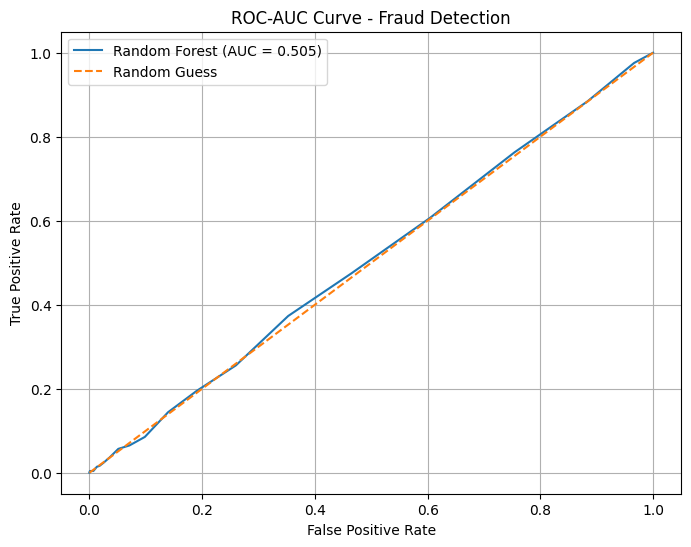

ROC-AUC Score: 0.505


In [20]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for the positive class (Fraudulent = 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Fraud Detection")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(auc_score, 3))
